# Imports

In [1]:
### import libraries and set plotting style

import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib import style
from matplotlib.colors import ListedColormap
from abc import ABC, abstractmethod

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from tqdm import tqdm

style.use('ggplot')

# Console

In [2]:
### Some useful functions and console game ###

# Create a full deck of cards (this includes n seperate) decks
def fill_deck(n=1):
  suits = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
  cards_list = ['A', '2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K']
  single_deck = [(card, suit) for suit in suits for card in cards_list]
  return single_deck * n

# Calculate value of one card
def card_value(card):
  if card[0] in ['J', 'Q', 'K']:
    return 10
  elif card[0] == 'A':
    return 11
  else:
    return int(card[0])

# Calculate hand value and the number of active ace (aces that can still be used as 11 without busting. Note that we can have at most 1 active ace.)
def calculate_hand_value(hand):
  value = sum([card_value(card) for card in hand])
  aces = sum([1 if card[0]=='A' else 0 for card in hand]) # Number of aces
  # Reduce the value of aces if over 21
  while value > 21 and aces > 0:
    value -= 10
    aces -= 1

  return value, aces

# Display hand
def display_hand(hand, owner="Player"):
  print(f"{owner}'s hand: {[card for card in hand]} (Value: {calculate_hand_value(hand)[0]})")

# Next action of human player
def player_action(splittable, double_flag):
  actions = ['hit', 'stand']
  if splittable:
    actions.append('split')

  if double_flag:
    actions.append('double')

  while True:
    action = input(f"Do you want to {', '.join(actions[:-1])} or {actions[-1]}? ").lower()
    if action in actions:
      return action
    else:
      print("Invalid input.")

# Human player chooses betting amount (integer)
def player_bet(maxbet=1):
  bettingDone = False
  while not bettingDone:
    try:
      bet = int(input("\nBetting amount: "))
      if bet > 0 and bet <= maxbet:
        bettingDone = True
      else:
        print(f"\nBetting amount needs to be between 1\u20ac and {maxbet}\u20ac")
    except ValueError:
      print("\nInvalid betting amount!")
  return bet

# Main game logic. If you want an agent to be the player then you need to pass him as an argument.
def blackjack_console(agent = None, max_bet = 100):
  print("Welcome to Blackjack!")
  print("\nMax bet is: ", max_bet,"\u20ac")
  deck = fill_deck()
  random.shuffle(deck)
  agent.reset_env()

  # Current game (each iteration is a new game with the same deck)
  while True:
    choice = input("Do you wish to play a new game? ['y'/'n']: ").lower()
    # If invalid input assume 'y'
    if choice == 'n':
      break

    # Start new game. If number of cards left <=10 reshuffle deck.
    if len(deck) <= 10:
      deck = fill_deck()
      random.shuffle(deck)
      if agent is not None:
        agent.reset_env()

    doubled_bet = False # Flag that shows if the bet is doubled

    print(f"Number of cards left in deck {len(deck)}")

    if agent is None:
      bet = player_bet(max_bet)
    else :
      bet = agent.place_bet(len(deck)) # Get bet
      print(f"\nBetting amount: {bet}\n")

    # Initial hands
    p_hand = [deck.pop(), deck.pop()]
    dealer_hand = [deck.pop(), deck.pop()]

    # Need to update count in case this is an agent
    if agent is not None:
      agent.update_env(p_hand[0])
      agent.update_env(p_hand[1])
      agent.update_env(dealer_hand[0])

    print(f"Dealer's first card: {dealer_hand[0]} \n")

    # Check for natural blackjack. Game ends after following checks.
    if calculate_hand_value(p_hand)[0] == 21:
      display_hand(p_hand)
      # Check if necessary to check dealer's second card
      if card_value(dealer_hand[0]) == 10 or card_value(dealer_hand[0]) == 11:
        display_hand(dealer_hand, "Dealer")
        if agent is not None:
          agent.update_env(dealer_hand[1])
        dealer_sum = calculate_hand_value(dealer_hand)[0]
        # Check if delaer also has 21, in which case it is a draw
        if dealer_sum == 21:
          print("It's a tie!")
          continue
      # If we get here then it means the player has a natural blackjack (3:2 payoff)
      print(f"Natural Blackjack! Player wins {1.5*bet}\u20ac !\n")
      continue

    # Additional variable used for splitting
    hands = [p_hand]
    bets = [bet]
    results = []
    current_hand = 0

    # Loop to go through all hands
    while current_hand < len(hands):
      print(f"--- Playing Hand {current_hand+1} ---")

      # Player's turn
      while True:
        player_hand = hands[current_hand]
        display_hand(player_hand)
        player_sum, aces = calculate_hand_value(player_hand)
        if player_sum > 21:
          print(f"Bust! Player loses {bets[current_hand]}\u20ac !\n")
          results.append(-bets[current_hand])
          break
        elif player_sum == 21:
          # Player stops and it's dealer's turn to check if he gets 21
          results.append('pending')
          break

        # If the bet is doubled only one more card can be drawn
        if doubled_bet:
          print("")
          results.append('pending')
          break

        # Check if player is allowed to 'double' (starting hand) or 'split' (starting hand and same card values)
        double_flag = (len(player_hand) == 2)
        splittable = ( len(player_hand) == 2 and ( card_value(player_hand[0]) == card_value(player_hand[1]) ) )

        if agent is None:
          action = player_action(splittable, double_flag)
        else:
          state = (player_sum, aces, card_value(dealer_hand[0]), splittable, double_flag, bets[current_hand])
          action = agent.choose_action(state, len(deck))
          print(state)
          print(action)

        doubled_bet = True if action == 'double' else False

        if doubled_bet:
          bets[current_hand] *= 2

        print("")
        if action == 'hit' or action == 'double':
          player_hand.append(deck.pop())

          # Need to update count in case this is an agent
          if agent is not None:
            agent.update_env(player_hand[-1])

        elif action == 'split':
          # Replace current hand and insert the second one
          hands[current_hand] = [player_hand[0]]
          hands.insert(current_hand+1, [player_hand[1]])
          # Append same bet (for second hand)
          bets.append(bets[current_hand])

          # Add a card to each hand and update potential agent
          new_card1 = deck.pop()
          new_card2 = deck.pop()
          if agent is not None:
            agent.update_env(new_card1)
            agent.update_env(new_card2)

          hands[current_hand].append(new_card1)
          hands[current_hand + 1].append(new_card2)

          print("New hands:")
          display_hand(hands[current_hand], "Player")
          display_hand(hands[current_hand+1], "Player")

          # If we splitted aces then only one more card allowed to draw, i.e. no more actions for the splitted hands.
          if card_value(player_hand[0]) == 11:
            current_hand += 2
            results.append('pending')
            results.append('pending')
            print("")
            break


          print(f"\n--- Playing Hand {current_hand+1} ---")

        else: # action == 'stand'
          results.append('pending')
          break

      # Move to next hand
      current_hand += 1

    # DONE WITH PLAYER HANDS

    # If all player hands are terminal (busted), no need to check dealer.
    if all(isinstance(x, int) for x in results):
      continue

    # Dealer's turn
    # If we get here then the second card gets revealed
    if agent is not None:
      agent.update_env(dealer_hand[1])

    while calculate_hand_value(dealer_hand)[0] < 17:
      dealer_hand.append(deck.pop())
      # Need to update count in case this is agent 2
      if agent is not None:
        agent.update_env(dealer_hand[-1])

    # Final dealer hand value
    dealer_value = calculate_hand_value(dealer_hand)[0]
    print(f"--- Results ---")
    display_hand(dealer_hand, "Dealer")

     # EVALUATE RESULTS PER HAND (necessary if split)
    for i, hand in enumerate(hands):
      if isinstance(results[i], int):  # Already bust. Don't print again
        continue

      player_value = calculate_hand_value(hand)[0]
      print(f"\nFinal Result for Hand {i+1}:")
      display_hand(hand, "Player")

      if dealer_value > 21:
        print(f"Dealer busts! Player wins {bets[i]}\u20ac !")
      elif player_value > dealer_value:
        print(f"Player wins {bets[i]}\u20ac (higher score) !")
      elif player_value < dealer_value:
        print(f"Player loses {bets[i]}\u20ac (lower score) !")
      else:
        print("It's a tie!")

    # New line
    print("")

In [ ]:
# Try the game in console
blackjack_console() # player

Welcome to Blackjack!

Max bet is:  100 €
Do you wish to play a new game? ['y'/'n']: y
Number of cards left in deck 52

Betting amount: 23
Dealer's first card: ('3', 'Diamonds') 

--- Playing Hand 1 ---
Player's hand: [('5', 'Clubs'), ('K', 'Hearts')] (Value: 15)
Do you want to hit, stand or double? hit

Player's hand: [('5', 'Clubs'), ('K', 'Hearts'), ('5', 'Spades')] (Value: 20)
Do you want to hit or stand? stand

--- Results ---
Dealer's hand: [('3', 'Diamonds'), ('K', 'Clubs'), ('4', 'Spades')] (Value: 17)

Final Result for Hand 1:
Player's hand: [('5', 'Clubs'), ('K', 'Hearts'), ('5', 'Spades')] (Value: 20)
Player wins 23€ (higher score) !

Do you wish to play a new game? ['y'/'n']: y
Number of cards left in deck 46

Betting amount: 20
Dealer's first card: ('8', 'Spades') 

--- Playing Hand 1 ---
Player's hand: [('3', 'Hearts'), ('9', 'Diamonds')] (Value: 12)
Do you want to hit, stand or double? hit

Player's hand: [('3', 'Hearts'), ('9', 'Diamonds'), ('A', 'Diamonds')] (Value: 13

# Blackjack Environment

In [3]:
# Abstract class for blackjack environment. The two environments for our assignment (task 1 and task 2) will inherit this class
class BlackjackEnvironment(ABC):

  def set_policy(self, Q_policy):
    self.Q_policy = Q_policy

  @abstractmethod
  def initialize_Q_table(self):
    pass

  @abstractmethod
  def initial_state(self, bet):
    pass

  @abstractmethod
  def blackjack_environment(self, state, action):
    pass

  # Choose action based on state withou counting_state and cards remaining in deck. Will be used by blackjack_console()
  @abstractmethod
  def choose_action(self, state, cards_remaining):
    pass

  # Policy based on full state. Will be used for testing
  @abstractmethod
  def policy(self, state):
    pass

  # Reset environment. Important for agent 2 to be able to be used in blackjack_console()
  @abstractmethod
  def reset_env(self):
    pass

  # Update environment. Important for agent 2 to be able to be used in blackjack_console()
  @abstractmethod
  def update_env(self, card):
    pass

# Tabular Q Learning

In [4]:
### Tabular Q-learning algorithm for a blackjack environment with actions 'hit', 'stand', 'double' and 'split'###
### Can learn betting policy as well as game policy
### Note that game policy is learned ignoring the bet to reduce state space, i.e. rewards are set as actual_reward / bet
### Betting policy is obviously learned by taking into account the actual rewards
### There is an option to either train both the game policy and the bet policy at the same time or
### to only train the bet policy (bet_only) if the game policy is pre-trained

def tabular_Q_learning(environment, bet_only = False, episodes = 10 ** 6, max_epsilon = 1, min_epsilon = 0.15, epsilon_decay = 0.999, gamma = 1, omega = 0.8):
  # We will use a dictionary. Each key will be a state and its value will be a dictionary of {action1 : [Q_value1, number_of_times_chosen1], ...}
  Q = environment.initialize_Q_table(bet_only= bet_only)
  epsilon = max_epsilon
  # Training loop. Note that we need to use try-except because there is a small chance the deck will run out even though it will have at least 11 cards.
  # In that case we disregard the current game and we start another episode with new deck.
  # We update episode at the end of try so the total number of episodes remain the same.
  episode = 0
  with tqdm(total=episodes, desc="Training Progress") as pbar:
    while episode < episodes:
      try:

        # --- BETTING PHASE ---
        counting_state = environment.initial_counting_state()

        # Epsilon-greedy bet selection (when using true count system)
        if random.uniform(0, 1) < epsilon:
            # Define bet tiers based on count
            if counting_state >= 3:
              # High -> favor exploring higher bets
              bet_candidates = [b for b in Q[counting_state] if b >= environment.max_bet * 0.6]
            elif counting_state <= -3:
              # Low -> favor exploring higher bets
              bet_candidates = [b for b in Q[counting_state] if b <= environment.max_bet * 0.5]
            else:
              bet_candidates = list(Q[counting_state].keys())  # Full range

            # Fall back if empty
            if not bet_candidates:
              bet_candidates = list(Q[counting_state].keys())

            # Choose random from this set
            bet = random.choice(bet_candidates)
        else:
            bet = max(Q[counting_state].keys(), key=lambda k: Q[counting_state].get(k)[0])

        # Starting game state with bet
        state, reward, terminal = environment.initial_state(bet)

        # Check if starting state is terminal (player_sum == 21)
        if terminal:
          # Update bet only when game has ended
          target = reward
          Q[counting_state][bet][1] += 1
          alpha = 1 / np.power(Q[counting_state][bet][1], omega)
          Q[counting_state][bet][0] = (1-alpha)*Q[counting_state][bet][0] + alpha * target

          episode += 1
          pbar.update(1)
          continue

        # --- GAME PHASE ---
        while not terminal:
          if not bet_only:
            # choose next game action using epsilon-greedy
            if random.uniform(0, 1) < epsilon:
              action = random.choice(list(Q[state].keys()))
            else:
              action = max(Q[state].keys(), key=lambda k: Q[state].get(k)[0]) # Find max action based on the first element of the tuple of its respective dictionary value
          else:
            action = environment.policy(state) # if bet_only get action from trained policy

          next_state, reward, terminal = environment.blackjack_environment(state, action)

          # if bet_only, we don't update any Q values corresponding to game policy
          if not bet_only:
            # Divide rewards by bet to learn game policy assuming constant bet sizes.
            if terminal:
              target = reward / bet
            else:
              best_next_action = max(Q[next_state].keys(), key=lambda k: Q[next_state].get(k)[0])
              if action != 'split':
                target = reward / bet + gamma * Q[next_state][best_next_action][0]
              else:
                # Note if we splitted then we have 2 new hands. Thus, we estimate the target using 2*Q[next_state].
                # A more accurate estimation would be Q' = Q[hand_1] + Q[hand_2] but for convenience and some practical reasons we use the previous formula instead
                target = reward / bet + gamma * 2 * Q[next_state][best_next_action][0]

            # Q-Learning update (number of times chosen and Q-value)
            # Note: set learning rate to alpha = 1/(t+1)^omega which satisfies the technical requirement
            # Check Learning rates for Q-learning by Eyal Even-Dar, Yishay Mansour
            Q[state][action][1] += 1
            alpha = 1 / np.power(Q[state][action][1], omega)
            Q[state][action][0] = (1-alpha)*Q[state][action][0] + alpha * target

          state = next_state

        # Update bet when game has ended
        target = reward
        Q[counting_state][bet][1] += 1
        alpha = 1 / np.power(Q[counting_state][bet][1], omega)
        Q[counting_state][bet][0] = (1-alpha)*Q[counting_state][bet][0] + alpha * target

        # Update epsilon for next episode
        epsilon = max(min_epsilon, epsilon * epsilon_decay)
        episode += 1
        pbar.update(1)

      except IndexError:
        continue

  # Done with training. Convert Q table to decision table
  Q_policy = {k:max(v.keys(), key=lambda a: v.get(a)[0]) for (k,v) in Q.items()}
  return Q_policy


# Test

In [5]:
### Test policy of an environment (based on function choose_action of the environment/agent)
def test(environment,episodes = 10 ** 6):
  # Keep track of wins/losses/ties
  wins = 0
  losses = 0
  episode = 0
  # Testing loop. For similar reasons use try-except.
  with tqdm(total=episodes, desc="Testing Progress") as pbar:
    while episode < episodes:
      try:
        bet = environment.place_bet()

        state, reward, terminal = environment.initial_state(bet, environment.bet_in_state)
        # If we drew immediately a 21 then the initial state is terminal (either win or draw).
        if terminal:
          episode += 1
          pbar.update(1)
          wins += reward
          continue

        terminal = False
        while not terminal:
          action = environment.policy(state)
          next_state, reward, terminal = environment.blackjack_environment(state, action)
          state = next_state

        if reward > 0:
          wins += reward
        elif reward < 0:
          losses -= reward

        # Update episode number and progress bar
        episode += 1
        pbar.update(1)
      except IndexError:
        continue

  wins = wins
  losses = losses
  return wins, losses

# Task 1

In [6]:
### Environment class for task 1 (with card counting, potentially multiple decks deck and reshuffling when 10 or less cards) ###
### In this case our state space is given by (our sum, active aces, counting state, dealer first card, splittable, double_flag, bet)
### Note: -> splittable and double_flag are booleans that represent whether the player can use 'split' and 'double' respectively
###       -> counting state will be 1 if in high state, 0 if in neutral state, -1 if in low state
###       -> state[6] (bet) will always be 1 for task 1 (ignore bet state for smaller state space in tabular learning)
###          instead use self.bet to calculate correct rewards
###       -> state[6] will be used normally in DQN for richer state representation
###       -> now that doubling and splitting is allowed considering all possible sums below 12 may be beneficial

class BlackjackTask1(BlackjackEnvironment):

  def __init__(self, high_threshold = 5, low_threshold = -5, number_of_decks = 1,  max_bet = 100):
    # Keep track of the state of the deck and the current count of the "Hi-Lo" system
    super().__init__()
    self.high_threshold = high_threshold
    self.low_threshold = low_threshold
    self.count_states = [1, 0, -1] # Hi-Lo system

    self.number_of_decks = number_of_decks
    self.max_bet = max_bet
    self.bet_actions = list(range(1, max_bet + 1)) # Action space for bets
    self.bet = 1 # bet of current game (used to calculate rewards)
    self.bet_in_state = False # bet not added in state space

    self.deck = fill_deck(number_of_decks)
    random.shuffle(self.deck)
    # Keep track of the player hands (Needed for split action).
    # This is a list of hands since after splitting we have two different hands that may split again.
    self.dealer_hand = []
    self.count = 0
    self.Q_policy = {}
    self.double_mult = [1]

    # Flag that indicates we have chosen split and list that stores the following hands to be played.
    self.split_flag = False
    self.next_hands = []
    self.current_hand = 0 # index for current hand in next_hands

  def reset_env(self):
    self.count = 0
    self.double_mult = [1]
    self.deck = fill_deck(self.number_of_decks)
    random.shuffle(self.deck)

  def update_env(self, card):
    if card[0] in ['2', '3', '4', '5', '6']:
      self.count += 1
    elif card[0] in ['10', 'J', 'Q', 'K', 'A']:
      self.count -= 1

  # Initialize the Q table that will be used by the tabular q learning.
  def initialize_Q_table(self, bet_only = False):
    Q = {}

    ### Create betting states
    for counting_state in self.count_states:
      Q[counting_state] = {key: [0, 0] for key in self.bet_actions}

    if bet_only:
      return Q

    # Note that since this is used for tabular Q learning state[6] is useless (always 1 and thus ignored)

    ### Create all states with splittable False and double True (i.e. starting hand but without pair of same cards)
    # Without active ace (min sum is 2+3). Note: max sum is 19 since 20 is unreachable with only 2 cards, no ace and not splittable
    for player_sum in range(5, 20):
      for counting_state in self.count_states:
        for dealer_card in range(2, 12):
          state = (player_sum, 0, counting_state, dealer_card, False, True, 1)
          Q[state] = {'hit': [0, 0], 'stand': [0, 0], 'double': [0, 0]} # q value and number of times chosen

    # With active ace (min sum is A+2, i.e. 13 )
    for player_sum in range(13, 21):
      for counting_state in self.count_states:
        for dealer_card in range(2, 12):
          state = (player_sum, 1, counting_state, dealer_card, False, True, 1)
          Q[state] = {'hit': [0, 0], 'stand': [0, 0], 'double': [0, 0]} # q value and number of times chosen

    ### Create all states with splittable False and double False (i.e. not starting hand or in other words at least 3 cards)
    # Without active ace (min sum is 2+2+2)
    for player_sum in range(6, 21):
      for counting_state in self.count_states:
        for dealer_card in range(2, 12):
          state = (player_sum, 0, counting_state, dealer_card, False, False, 1)
          Q[state] = {'hit': [0, 0], 'stand': [0, 0]} # q value and number of times chosen

    # With active ace (min sum is A+A+A, i.e. 13)
    for player_sum in range(13, 21):
      for counting_state in self.count_states:
        for dealer_card in range(2, 12):
          state = (player_sum, 1, counting_state, dealer_card, False, False, 1)
          Q[state] = {'hit': [0, 0], 'stand': [0, 0]} # q value and number of times chosen

    values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11] # All possible card values
    ### Create the rest of the states with splittable True and double True (starting hand and pair of cards with same value)
    for val in values:
      for counting_state in self.count_states:
        for dealer_card in range(2, 12):
          player_sum = 2*val if val != 11 else 12
          aces = 1 if val == 11 else 0
          state = (player_sum, aces, counting_state, dealer_card, True, True, 1)
          Q[state] = {'hit': [0, 0], 'stand': [0, 0], 'double': [0, 0], 'split': [0, 0]}

    return Q


  # Returns the counting state of the next new game
  def initial_counting_state(self):
    # Need to check if we have to reset the counting state
    if len(self.deck) <= 10:
      self.reset_env()

    return self.count_state()


  # Returns a new initial state (new game), reward (0 if non terminal) and terminal (True if player_sum == 21)
  # bet_in_state tells us whether we want to consider bet as part of the state or disregard it and set state[6] to 1
  # This will be False in task 1 to train tabular Q learning with constant bet
  def initial_state(self, bet = 1, bet_in_state = False):
    # Check if we need to reshuffle and reset count
    if len(self.deck) <= 10:
      self.reset_env()

    # Set bet of current game
    self.bet = bet

    # Reset multiplier
    self.double_mult = [1]

    # Reset split variables
    self.split_flag = False
    self.next_hands = []
    self.current_hand = 0

    # Initial hands
    player_hand = [self.deck.pop(), self.deck.pop()]
    self.dealer_hand = [self.deck.pop(), self.deck.pop()] # need to remember for when it's the dealer's turn

    # Now both hands are finalized for the starting state. Time to update our count
    for card in player_hand:
      self.update_env(card)

    self.update_env(self.dealer_hand[0])

    # Find the current counting state
    counting_state = self.count_state()

    # Check if splittable (pair and same value)
    if card_value(player_hand[0]) == card_value(player_hand[1]):
      splittable = True
    else:
      splittable = False

    player_sum, aces = calculate_hand_value(player_hand)

    terminal = False
    reward = 0
    # Lastly check if new state is terminal (player_sum == 21) and if it's natural blackjack
    if player_sum == 21:
      terminal = True
      # Check if dealer has a 10 or an ace in which case he reveals his second card
      if card_value(self.dealer_hand[0]) == 10 or card_value(self.dealer_hand[0]) == 11:
        self.update_env(self.dealer_hand[1])
        dealer_sum = calculate_hand_value(self.dealer_hand)[0]
        # Check if dealer doesn't have 21, then natural blackjack
        if dealer_sum != 21:
          reward = 1.5 * bet
      else:
        # If we get here then player has a natural blackjack (3:2 payoff)
        reward = 1.5 * bet

    # Practically removes bet from state space
    if not bet_in_state:
      bet = 1

    # Return state (double_flag True because staring hand), reward, terminal
    return (player_sum, aces, counting_state, card_value(self.dealer_hand[0]), splittable, True, bet), reward, terminal


  # Calculate new hand value (sum and aces) after drawing a new card
  def calculate_new_hand(self, player_sum, aces, new_card):
    new_card = new_card[0] # ignore suit
    # New sum
    if new_card in ['J', 'Q', 'K']:
      player_sum += 10
    elif new_card == 'A':
      player_sum += 11
      aces += 1
    else:
      player_sum += int(new_card)

    # Reduce the value of available aces if over 21
    while player_sum > 21 and aces > 0:
      player_sum -= 10
      aces -= 1

    return player_sum, aces

  # Find current counting state
  def count_state(self):
    # Estimate decks remaining
    decks_remaining = max(len(self.deck) / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining
    if true_count > self.high_threshold:
        counting_state = 1
    elif true_count < self.low_threshold:
      counting_state = -1
    else:
      counting_state = 0

    return counting_state

  # After all split hands are done evaluate the total reward.
  def evalute_split_hands(self):
    sums = [state[0] for state in self.next_hands]
    # Check if at least one hand is non-terminal (i.e. if dealer needs to reveal his hand and potentially draw)
    check = any(num <= 21 for num in sums)

    dealer_sum = self.next_hands[0][3] # dealer's first card
    if check:
      dealer_aces = 1 if dealer_sum == 11 else 0 # Check if first card was ace
      second_card_read = False # Flag to check if we have seen the second card from self.dealer_hand
      while dealer_sum < 17:
        # If we havent seen the second card, no need to draw from the deck
        if not second_card_read:
          new_card = self.dealer_hand[1]
          second_card_read = True
        else:
          new_card = self.deck.pop()

        self.update_env(new_card)
        # Update dealer_sum
        dealer_sum, _ = self.calculate_new_hand(dealer_sum, dealer_aces, new_card)

    reward = 0
    for index, state in enumerate(self.next_hands):
      if state[0] > dealer_sum or dealer_sum > 21:
        reward += self.bet * self.double_mult[index]
      elif state[0]== dealer_sum:
        continue
      else:
        reward -= self.bet * self.double_mult[index]

    return reward

  # Returns the next state, reward and terminal (boolean)
  def blackjack_environment(self, state, action):
    # Counting state is unnecessary. We will reevaluate based on count and not based on currnet counting_state
    player_sum, aces, _ , dealer_card, splittable, double_flag, bet = state

    if action == 'hit' or action == 'double':
      # Draw card and update count
      new_card = self.deck.pop()
      self.update_env(new_card)

      # Update player_sum and aces
      player_sum, aces = self.calculate_new_hand(player_sum, aces, new_card)

      # Find the current counting state
      counting_state = self.count_state()

      # If action is double, modify reward multiplier
      self.double_mult[self.current_hand] = 2 if action == 'double' else 1

      # We can only split if we have 2 cards. Therefore, after drawing splittable becomes false. Similarly for double.
      next_state = (player_sum, aces, counting_state, dealer_card, False, False, bet)

      # Update hand in list next_hands
      if self.split_flag:
        self.next_hands[self.current_hand] = next_state

      # Done with this split hand. Check next
      if player_sum >= 21 and self.split_flag:
        self.current_hand += 1
        while self.current_hand < len(self.next_hands) and self.next_hands[self.current_hand][0] >= 21:
          self.current_hand += 1

        if self.current_hand == len(self.next_hands): # No other hand to check
          reward = self.evalute_split_hands()
          return self.next_hands[-1], reward, True
        else:
          # Update counting state before moving to next hand
          counting_state = self.count_state()
          player_sum, aces, _ , dealer_card, splittable, double_flag, bet = self.next_hands[self.current_hand]
          next_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)

          return next_state, 0, False

      if player_sum > 21:  # Bust
        return next_state, -self.bet * self.double_mult[self.current_hand], True

      # Choosing double is like hit and stand. Similarly if our sum is equal to 21 we stop and give the dealer the chance to get 21 as well.
      if player_sum == 21 or action == 'double':
        return self.blackjack_environment(next_state, 'stand')

      return next_state, 0, False # No bust. Continue game

    elif action == 'split':
      # Note that we can get here only if state is splittable
      if not splittable:
        raise Exception("Invalid split")

      # Split our hand into 2, draw one for each hand and continue (2 new states)
      single_card = 11 if player_sum == 12 and aces == 1 else int(player_sum/2) # Find single card value. Check if it was aces otherwise do player_sum/2

      new_card = self.deck.pop()
      self.update_env(new_card)
      sum1, aces1 = self.calculate_new_hand(single_card, aces, new_card)
      splittable1 = (card_value(new_card) == single_card)

      new_card = self.deck.pop()
      self.update_env(new_card)
      sum2, aces2 = self.calculate_new_hand(single_card, aces, new_card)
      splittable2 = (card_value(new_card) == single_card)

      # Find new counting state. Note that this state will be valid only for hand 1. Hand 2 will need to reevaluate
      counting_state = self.count_state()

      # New states for each hand. Note that we can double after splitting (each hard is like a new starting hand)
      state1 = (sum1, aces1, counting_state, dealer_card, splittable1, True, bet)
      state2 = (sum2, aces2, counting_state, dealer_card, splittable2, True, bet)

      # Activate flag that we have chosen split and store states. This is necessary to continue with hand 2 after we are down with hand 1.
      self.split_flag = True
      # Ensure that after split the correct amount of hands are added (if the hand was already a split one then replace the old and add one more)
      if len(self.next_hands) == 0:
        self.next_hands.insert(self.current_hand, state1)
      else:
        self.next_hands[self.current_hand] = state1

      self.next_hands.insert(self.current_hand+1, state2)

      self.double_mult.append(1)

      # If we splitted aces then only one more card allowed to draw, i.e. no more actions for the splitted hands.
      if single_card == 11:
        self.current_hand += 2

        # Check if another non terminal hand exists (shouldn't be possible when splitting aces but included for safety)
        while self.current_hand < len(self.next_hands) and self.next_hands[self.current_hand][0] >= 21:
          self.current_hand += 1

        # No other hand to check (should always be true)
        if self.current_hand == len(self.next_hands):
          reward = self.evalute_split_hands()
          return self.next_hands[-1], reward, True
        else:
          # Update counting state before moving to next hand
          counting_state = self.count_state()
          player_sum, aces, _ , dealer_card, splittable, double_flag, bet = self.next_hands[self.current_hand]
          next_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)

          return next_state, 0, False

      # First hand is terminal. Move to next
      if sum1 >= 21:
        self.current_hand += 1

        # Second hand terminal
        if sum2 >= 21:
          self.current_hand += 1

          # Check if another non terminal hand exists
          while self.current_hand < len(self.next_hands) and self.next_hands[self.current_hand][0] >= 21:
            self.current_hand += 1

          # No other hand to check
          if self.current_hand == len(self.next_hands):
            reward = self.evalute_split_hands()
            return self.next_hands[-1], reward, True
          else:
            # Update counting state before moving to next hand
            counting_state = self.count_state()
            player_sum, aces, _ , dealer_card, splittable, double_flag, bet = self.next_hands[self.current_hand]
            next_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)

            return next_state, 0, False

      # Return next hand
      return self.next_hands[self.current_hand], 0, False
    else:
      # Check if during split
      if self.split_flag:
        self.current_hand += 1
        while self.current_hand < len(self.next_hands) and self.next_hands[self.current_hand][0] >= 21:
          self.current_hand += 1

        # No other hand to check
        if self.current_hand == len(self.next_hands):
          reward = self.evalute_split_hands()
          return self.next_hands[-1], reward, True
        else:
          # Update counting state before moving to next hand
          counting_state = self.count_state()
          player_sum, aces, _ , dealer_card, splittable, double_flag, bet = self.next_hands[self.current_hand]
          next_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)

          return next_state, 0, False

      # Dealer's turn
      dealer_sum = dealer_card
      dealer_aces = 1 if dealer_sum == 11 else 0 # Check if first card was ace
      second_card_read = False # Flag to check if we have seen the second card from self.dealer_hand
      while dealer_sum < 17:
        # If we havent seen the second card, no need to draw from the deck
        if not second_card_read:
          new_card = self.dealer_hand[1]
          second_card_read = True
        else:
          new_card = self.deck.pop()

        self.update_env(new_card)

        # Update dealer_sum and dealer_aces
        dealer_sum, dealer_aces = self.calculate_new_hand(dealer_sum, dealer_aces, new_card)

      # Find the current counting state. This is actually unecessary since the next state is terminal
      counting_state = self.count_state()

      if dealer_sum > 21 or player_sum > dealer_sum:
        return (player_sum, aces, counting_state, dealer_card, False, False,bet), self.bet * self.double_mult[self.current_hand], True
      elif player_sum == dealer_sum:
        return (player_sum, aces, counting_state, dealer_card, False, False, bet), 0, True
      else:
        return (player_sum, aces, counting_state, dealer_card, False, False, bet), -self.bet * self.double_mult[self.current_hand], True

  # Choose next action based on (player sum, active aces, dealer's card, splittable). Need to ensure that the count is updated.
  # This is used by the console, so cards_remaining is needed for true count (deck of environment is different than deck of console).
  def choose_action(self, state, cards_remaining):
    player_sum, aces, dealer_card, splittable, double_flag, bet = state
    # Find the current counting state
    decks_remaining = max(cards_remaining / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining
    if true_count > self.high_threshold:
        counting_state = 1
    elif true_count < self.low_threshold:
      counting_state = -1
    else:
      counting_state = 0

    # This function is used when the agent is trained with tabular Q-learning
    # In that case bet is not considered an active part of the state
    bet = 1

    return self.Q_policy[(player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)]

  # Choose next action based on full state. This is used for testing.
  def policy(self, state):
    return self.Q_policy[state]

  # Betting policy. For task 1 this will always return 1 (max_bet = 1)
  def place_bet(self, cards_remaining = None):
    if cards_remaining is None:
      counting_state = self.initial_counting_state() # Used when called as part of the environment
    else:
      # Find the current counting state based in the number of cards remaining and the current count
      decks_remaining = max(cards_remaining / 52, 1)  # Avoid division by zero
      true_count = self.count / decks_remaining
      if true_count > self.high_threshold:
          counting_state = 1
      elif true_count < self.low_threshold:
        counting_state = -1
      else:
        counting_state = 0

    return self.Q_policy[counting_state]

In [ ]:
# Train our agent and set his policy for max_bet = 1
task1_env = BlackjackTask1(high_threshold = 3, low_threshold = -3, max_bet = 1)
Q2 = tabular_Q_learning(environment = task1_env, episodes = 10 ** 7)
task1_env.set_policy(Q2)

Training Progress: 100%|██████████| 10000000/10000000 [04:15<00:00, 39089.50it/s]


## Visualization of policy

In [7]:
### Visualize policy results of task 1 for a specific counting state. This code was based on the create_plots() function of https://gymnasium.farama.org/tutorials/training_agents/blackjack_tutorial/
# Note the visualization is done for the states defined by (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)
# where bet == 1
def visualize_policy(agent, counting_state, bet = 1, label = None):
  if label is None:
    if counting_state == 1:
      label = "High State"
    elif counting_state == -1:
      label = "Low State"
    else:
      label = "Neutral State"

  player_sum_without = list(range(5, 20))
  player_sum_no_ace_no_double = list(range(6, 21))
  player_sum_with = list(range(13, 21))
  dealer_card = list(range(2, 12))
  values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11] # All possible card values

  color_code = ListedColormap(["gray", "green", "orange", "blue"]) # Colors of 0, 1, 2, 3

  # Create data for the heatmap without active ace and with double ('stand' = 0, 'hit' = 1, 'double' = 2)
  data_without = np.zeros((len(dealer_card), len(player_sum_without)))
  for j, x in enumerate(player_sum_without):
    for i, y in enumerate(dealer_card):
      if agent.policy( (x,0, counting_state,y, False, True, bet) ) == 'double':
        data_without[i][j] = 2
      elif agent.policy( (x,0, counting_state,y, False, True, bet) ) == 'hit':
        data_without[i][j] = 1
      else :
        data_without[i][j] = 0

  # Create data for the heatmap with active ace and with double ('stand' = 0, 'hit' = 1, 'double' = 2)
  data_with = np.zeros((len(dealer_card), len(player_sum_with)))
  for j, x in enumerate(player_sum_with):
    for i, y in enumerate(dealer_card):
      if agent.policy( (x,1, counting_state,y, False, True, bet) ) == 'double':
        data_with[i][j] = 2
      elif agent.policy( (x,1, counting_state,y, False, True, bet) ) == 'hit':
        data_with[i][j] = 1
      else :
        data_with[i][j] = 0

  # Create data for the heatmap without active ace and without double ('stand' = 0, 'hit' = 1)
  data_no_ace_no_double = np.zeros((len(dealer_card), len(player_sum_no_ace_no_double)))
  for j, x in enumerate(player_sum_no_ace_no_double):
    for i, y in enumerate(dealer_card):
      if agent.policy( (x,0, counting_state,y, False, False, bet) ) == 'hit':
        data_no_ace_no_double[i][j] = 1
      else :
        data_no_ace_no_double[i][j] = 0

  # Create data for the heatmap with active ace and without double ('stand' = 0, 'hit' = 1)
  data_with_no_double = np.zeros((len(dealer_card), len(player_sum_with)))
  for j, x in enumerate(player_sum_with):
    for i, y in enumerate(dealer_card):
      if agent.policy( (x,1, counting_state,y, False, False, bet) ) == 'hit':
        data_with_no_double[i][j] = 1
      else :
        data_with_no_double[i][j] = 0

  # Create data for the heatmap with splittable pairs and with double ('stand' = 0, 'hit' = 1, 'double' = 2, 'split' = 3)
  data_split = np.zeros((len(dealer_card), len(values)))
  for j, val in enumerate(values):
    for i, y in enumerate(dealer_card):
      x = 2*val if val != 11 else 12
      aces = 1 if val == 11 else 0
      if agent.policy( (x,aces, counting_state,y, True, True, bet) ) == 'split':
        data_split[i][j] = 3
      elif agent.policy( (x,aces, counting_state,y, True, True, bet) ) == 'double':
        data_split[i][j] = 2
      elif agent.policy( (x,aces, counting_state,y, True, True, bet) ) == 'hit':
        data_split[i][j] = 1
      else :
        data_split[i][j] = 0

  fig, ax = plt.subplots(1, 3, figsize=(18, 5))


  sns.heatmap(data_without, annot=True, cmap=color_code, xticklabels=player_sum_without,
              yticklabels=dealer_card, cbar=False, ax=ax[0], vmin=0, vmax=3)
  ax[0].set_title(f"Policy for {label.lower()} and without active ace")
  ax[0].set_xlabel("Player sum")
  ax[0].set_ylabel("Dealer's first card")

  sns.heatmap(data_with, annot=True, cmap=color_code, xticklabels=player_sum_with,
              yticklabels=dealer_card, cbar=False, ax=ax[1], vmin=0, vmax=3)
  ax[1].set_title(f"Policy for {label.lower()} and with active ace")
  ax[1].set_xlabel("Player sum")
  ax[1].set_ylabel("Dealer's first card")

  sns.heatmap(data_split, annot=True, cmap=color_code, xticklabels=values,
              yticklabels=dealer_card, cbar=False, ax=ax[2], vmin=0, vmax=3)
  ax[2].set_title(f"Policy for {label.lower()} and splittable")
  ax[2].set_xlabel("Pair of card value")
  ax[2].set_ylabel("Dealer's first card")

  # Legend
  legend_elements = [
    Patch(facecolor="orange", edgecolor="black", label="Double"),
    Patch(facecolor="green", edgecolor="black", label="Hit"),
    Patch(facecolor="grey", edgecolor="black", label="Stand"),
    Patch(facecolor="blue", edgecolor="black", label="Split")
  ]
  ax[2].legend(handles=legend_elements, bbox_to_anchor=(1.3, 1))
  fig.suptitle(f"{label} with Double", fontsize=20, y = 1)

  fig, ax = plt.subplots(1, 2, figsize=(12, 5))

  sns.heatmap(data_no_ace_no_double, annot=True, cmap=color_code, xticklabels=player_sum_no_ace_no_double,
              yticklabels=dealer_card, cbar=False, ax=ax[0], vmin=0, vmax=3)
  ax[0].set_title(f"Policy for {label.lower()} and without active ace")
  ax[0].set_xlabel("Player sum")
  ax[0].set_ylabel("Dealer's first card")

  sns.heatmap(data_with_no_double, annot=True, cmap=color_code, xticklabels=player_sum_with,
              yticklabels=dealer_card, cbar=False, ax=ax[1], vmin=0, vmax=3)
  ax[1].set_title(f"Policy for {label.lower()} and with active ace")
  ax[1].set_xlabel("Player sum")
  ax[1].set_ylabel("Dealer's first card")

  # Legend
  legend_elements = [
    Patch(facecolor="green", edgecolor="black", label="Hit"),
    Patch(facecolor="grey", edgecolor="black", label="Stand")
  ]
  ax[1].legend(handles=legend_elements, bbox_to_anchor=(1.3, 1))
  fig.suptitle(f"{label} without Double", fontsize=20, y = 1)

  plt.show()

### High Counting State

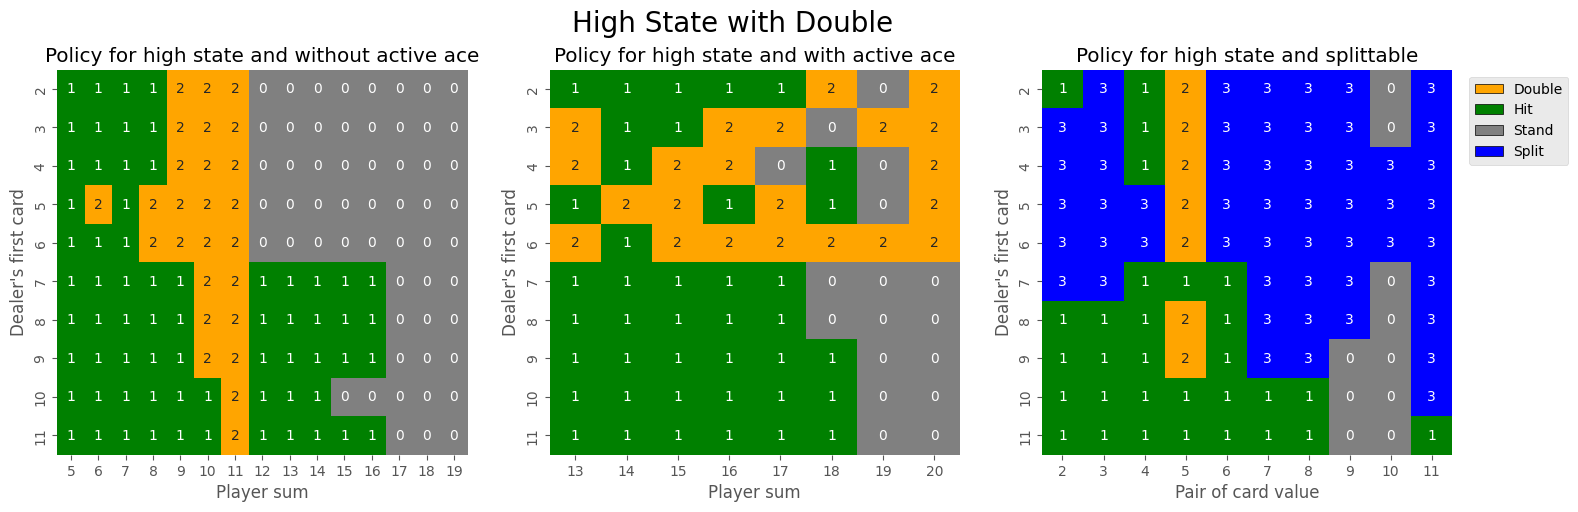

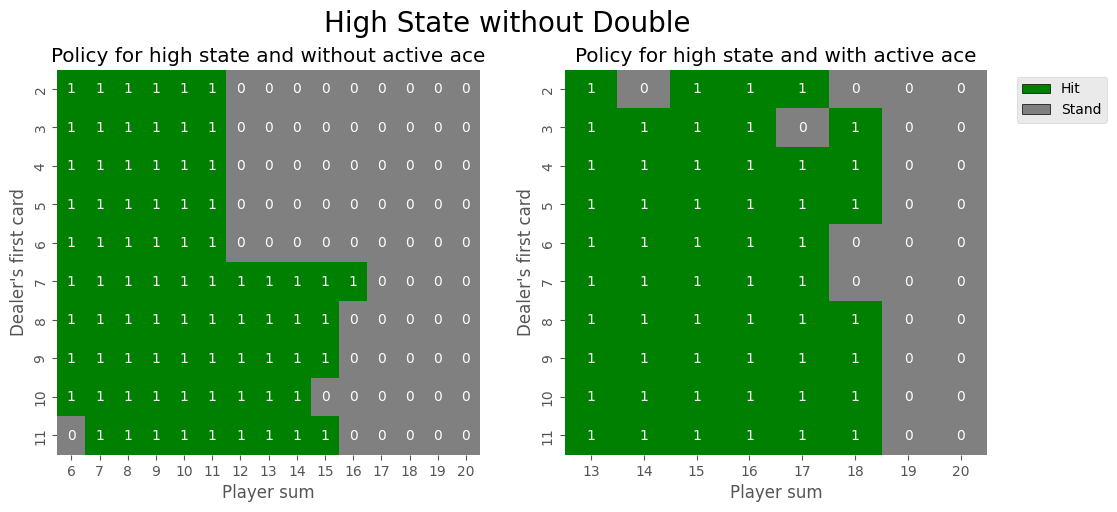

In [ ]:
visualize_policy(task1_env, 1)

### Neutral Counting State

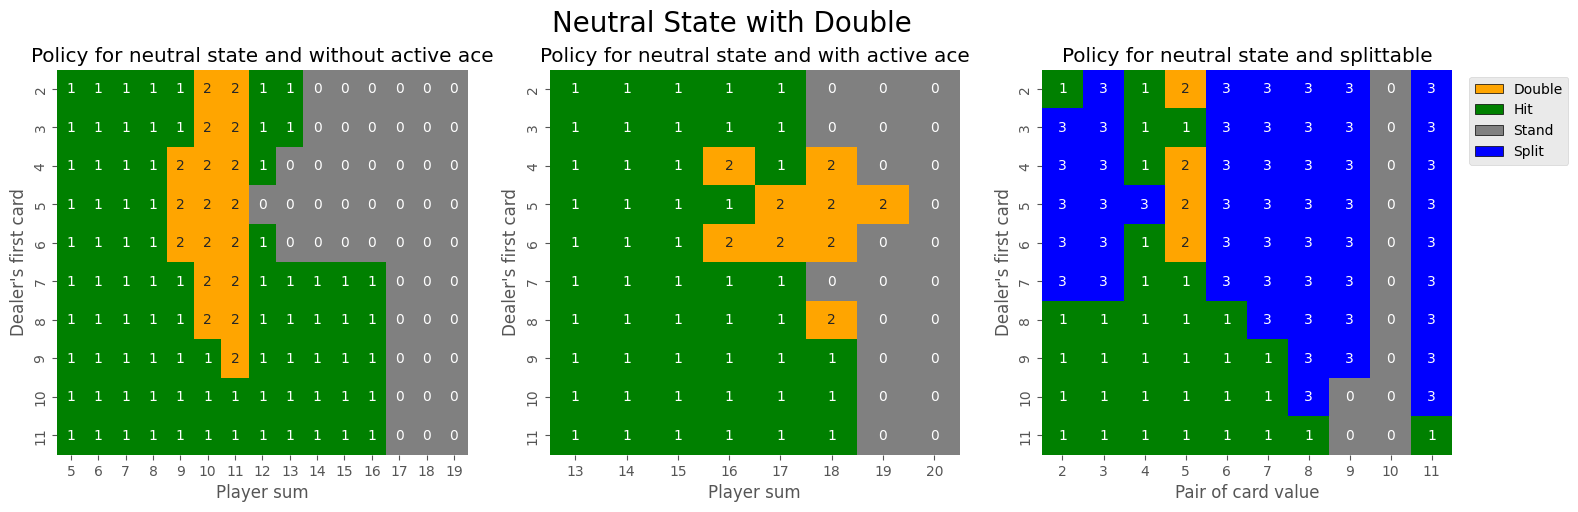

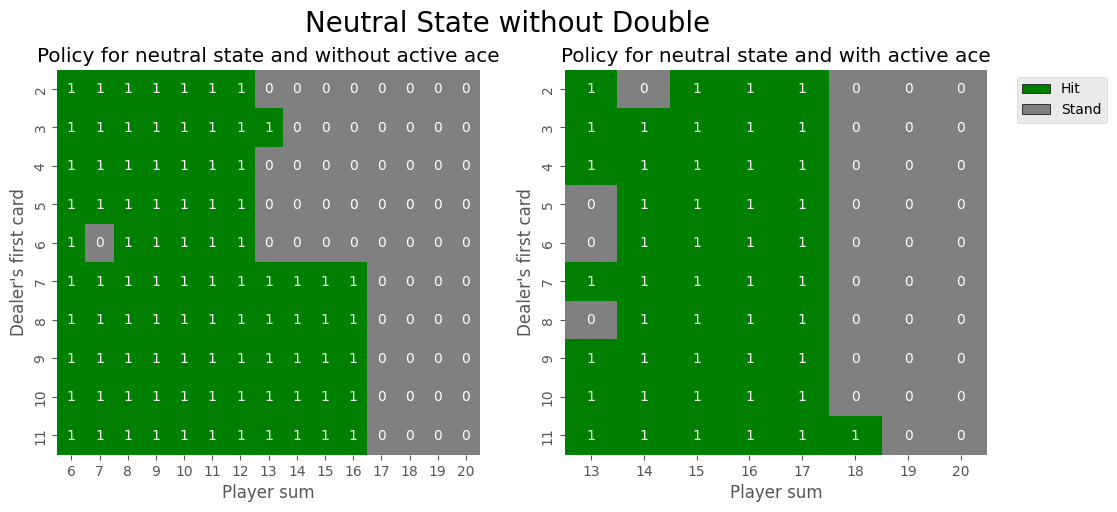

In [ ]:
visualize_policy(task1_env, 0)

### Low Counting State

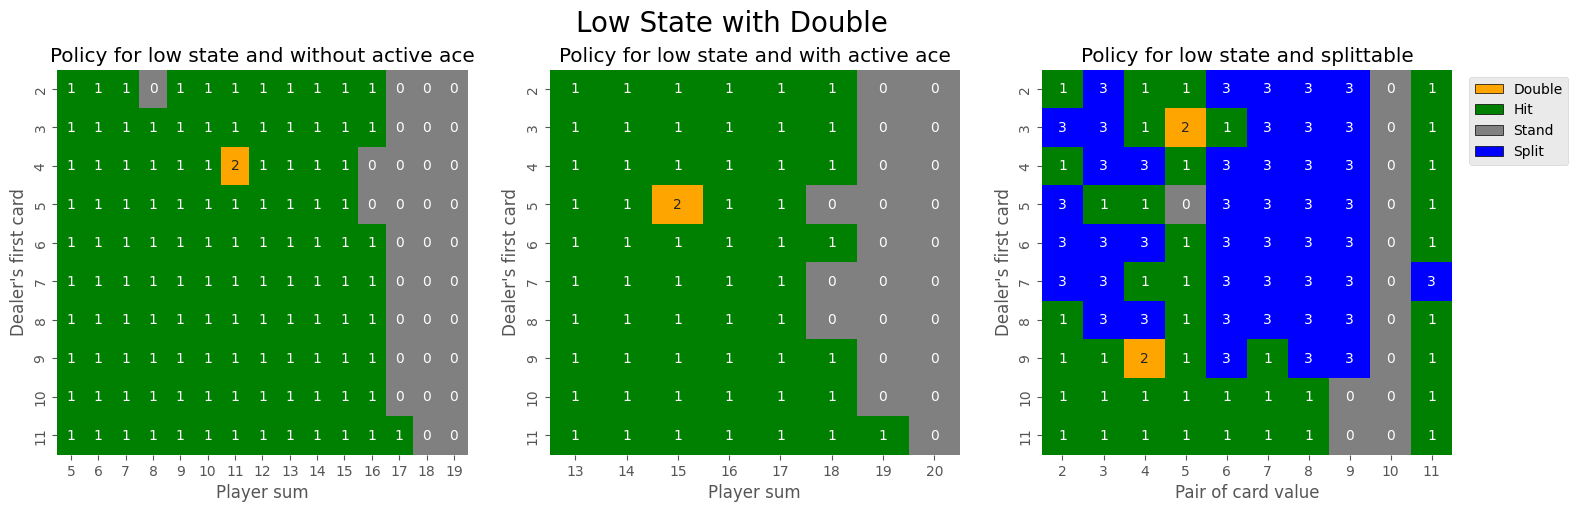

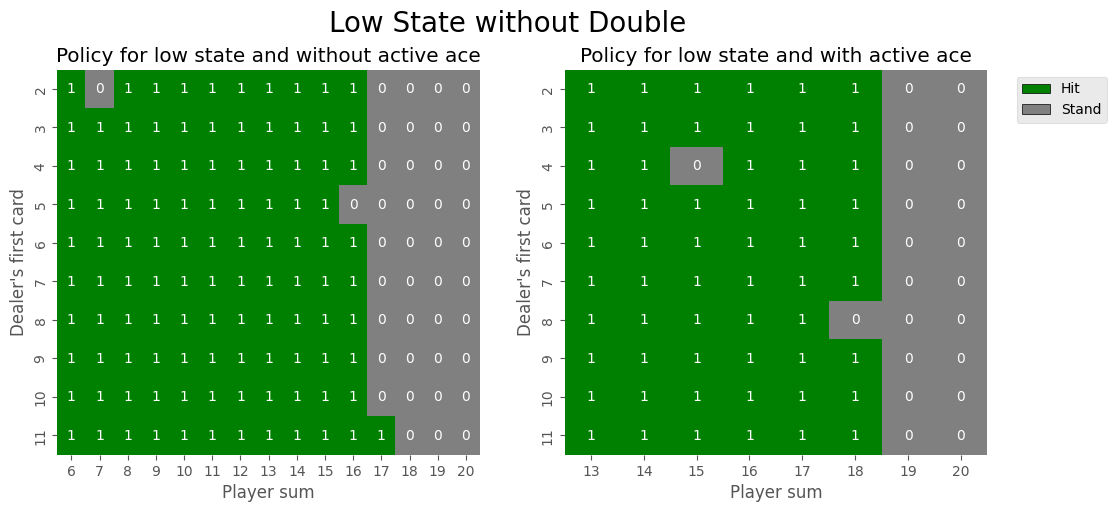

In [ ]:
visualize_policy(task1_env, -1)

## Test tabular Q Learning

In [ ]:
# Test results for task 1
episodes = 10 ** 7
wins, losses = test(task1_env, episodes)

Testing Progress: 100%|██████████| 10000000/10000000 [01:42<00:00, 97297.01it/s]


In [ ]:
# Profit per episode
print(f"Results for task 1:\nProfit per episode: {(wins-losses)/episodes}")

Results for task 1:
Profit per episode: 0.01152315


# Task 2

In [8]:
max_bet = 40
number_of_decks = 1

## Tabular Q-Learning with True Count


In [9]:

### Environment class for task 2 (with card counting, potentially multiple deck and reshuffling when 10 or less cards) ###
### In this case our state space is the same as before but Q_policy is a neural network instead of a dictionary
### Counting state will be the true count itself instead of simple Hi-Lo.
### In this case the thresholds are used to clip true_count in [low, high].

class BlackjackTrueCount(BlackjackTask1):

  def __init__(self, high_threshold = 6, low_threshold = -6, number_of_decks = 1, max_bet = 10):
    super().__init__(high_threshold, low_threshold, number_of_decks, max_bet)
    self.count_states = list(range(low_threshold, high_threshold+1))


  # Find current counting state. Overwrite to keep track of discrete true count instead of Hi-Lo.
  def count_state(self):
    # Estimate decks remaining
    decks_remaining = max(len(self.deck) / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining
    tc_clipped = max(min(true_count, self.high_threshold), self.low_threshold)

    return int(tc_clipped)

  # Choose next action based on (player sum, active aces, dealer's card, splittable). Need to ensure that the count is updated.
  # This is used by the console, so cards_remaining is needed for true count (deck of environment is different than deck of console).
  def choose_action(self, state, cards_remaining):
    player_sum, aces, dealer_card, splittable, double_flag, bet = state
    # Find the current counting state
    decks_remaining = max(cards_remaining / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining
    tc_clipped = max(min(true_count, self.high_threshold), self.low_threshold)
    counting_state = int(tc_clipped)

    # This function is used when the agent is trained with tabular Q-learning
    # In that case bet is not considered an active part of the state
    bet = 1

    return self.Q_policy[(player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)]

  # Betting policy. For task 1 this will always return 1 (max_bet = 1)
  def place_bet(self, cards_remaining = None):
    if cards_remaining is None:
      counting_state = self.initial_counting_state() # Used when called as part of the environment
    else:
      # Find the current counting state based in the number of cards remaining and the current count
      decks_remaining = max(cards_remaining / 52, 1)  # Avoid division by zero
      true_count = self.count / decks_remaining
      tc_clipped = max(min(true_count, self.high_threshold), self.low_threshold)
      counting_state = int(tc_clipped)

    return self.Q_policy[counting_state]



In [14]:
# Train only the game policy of our agent first (set max_bet = 1) since it is not affected by bet policy anyway
# Note that here the thresholds are for clipping true count
task2_env_tabular = BlackjackTrueCount(high_threshold = 7, low_threshold = -7, number_of_decks=number_of_decks, max_bet = 1)
Q = tabular_Q_learning(environment = task2_env_tabular, episodes = 10 ** 7, epsilon_decay = 0.99995)

# Then train the bet policy seperately.
# This improves performance because the game policy is already converged and the agent doesn't get punished for higher bets
task2_env_tabular = BlackjackTrueCount(high_threshold = 7, low_threshold = -7, number_of_decks=number_of_decks, max_bet = max_bet)
task2_env_tabular.set_policy(Q) # set game policy
Q_bet = tabular_Q_learning(environment = task2_env_tabular, bet_only= True, episodes = 10 ** 7, epsilon_decay = 0.99995)

# Update bet policy
for key, val in Q_bet.items():
  Q[key] = val

task2_env_tabular.set_policy(Q)

Training Progress: 100%|██████████| 10000000/10000000 [04:40<00:00, 35593.00it/s]


In [15]:
# Check betting policy based on our simple true count system
print("---- Betting Policy: ----")
for counting_state in task2_env_tabular.count_states:
  label = f"true count {counting_state}"
  bet = task2_env_tabular.Q_policy[counting_state]
  print(f"Bet for {label}: {bet}")

---- Betting Policy: ----
Bet for true count -7: 1
Bet for true count -6: 1
Bet for true count -5: 1
Bet for true count -4: 1
Bet for true count -3: 1
Bet for true count -2: 31
Bet for true count -1: 1
Bet for true count 0: 21
Bet for true count 1: 36
Bet for true count 2: 38
Bet for true count 3: 37
Bet for true count 4: 35
Bet for true count 5: 37
Bet for true count 6: 35
Bet for true count 7: 40


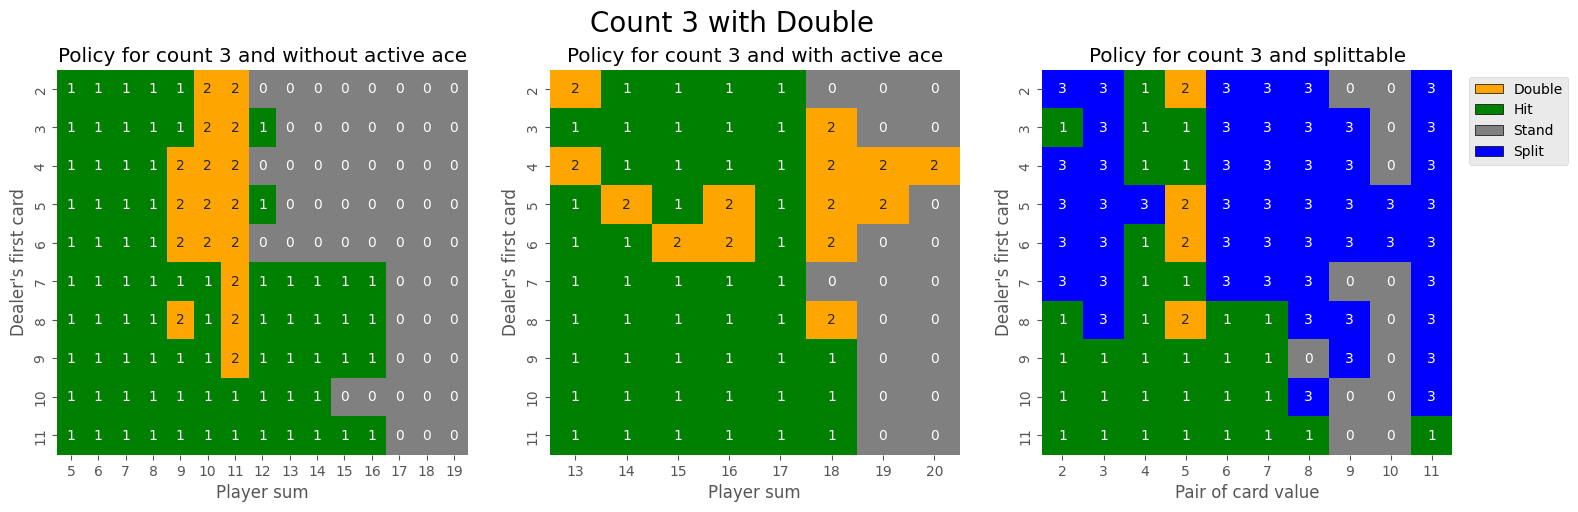

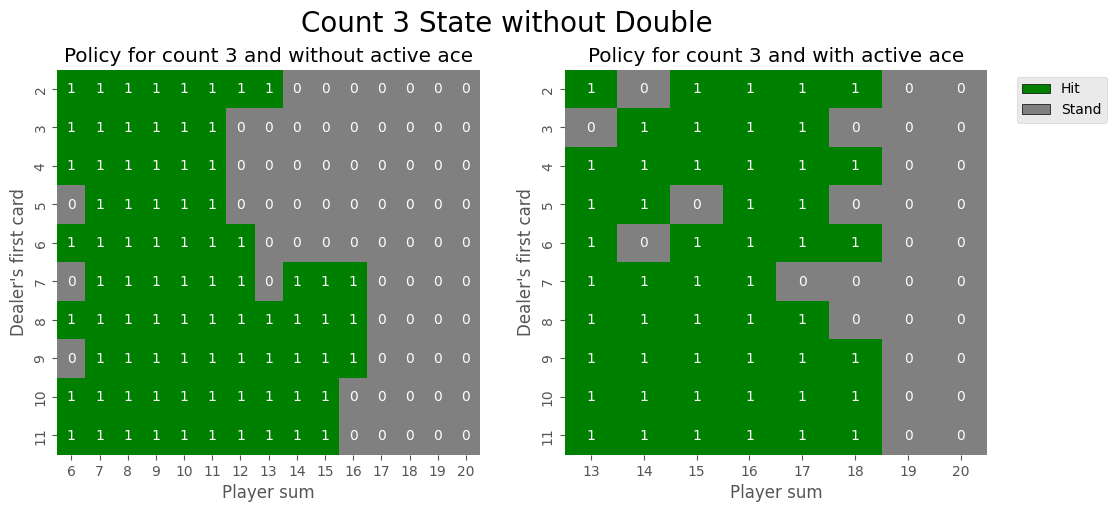

In [ ]:
# Use this to check the policy for specific counting state. This policy should be close to respective task 1 policy
counting_state = 3
visualize_policy(task2_env_tabular, counting_state = counting_state, label = f"Count {counting_state}")

In [16]:
# Test results for task 2 tabular
episodes = 10 ** 7
wins, losses = test(task2_env_tabular, episodes)

Testing Progress: 100%|██████████| 10000000/10000000 [02:26<00:00, 68334.96it/s]


In [17]:
# Profit per episode
print(f"Results for task 2 with tabular Q-learning:\nProfit per episode: {(wins-losses)/episodes}")

Results for task 2 with tabular Q-learning:
Profit per episode: 0.44654105


## DQN

In [ ]:
### Some useful functions for the DQN and the choose_action of the environment

# State Preprocessing for game states
def state_to_tensor(state, environment):
    player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet = state
    player_total = player_sum / 20
    dealer_total = dealer_card / 11
    can_split = 1.0 if splittable else 0.0
    can_double = 1.0 if double_flag else 0.0
    normal_bet = bet / environment.max_bet

    # If already in list form (complete counting_state)
    if isinstance(counting_state, list):
        normal_count = [card_occurrence/(4*environment.number_of_decks) for card_occurrence in counting_state[:-1]]
        normal_count.append(counting_state[-1] / (52 * environment.number_of_decks))
        return torch.tensor([player_total, aces, *normal_count, dealer_total, can_split, can_double, normal_bet], dtype=torch.float32)
    else:
        # True count value
        normal_count = 2 * (counting_state - environment.low_threshold) / (environment.high_threshold - environment.low_threshold) - 1
        return torch.tensor([player_total, aces, normal_count, dealer_total, can_split, can_double, normal_bet], dtype=torch.float32)

# State Preprocessing for betting states (only counting state)
def counting_state_to_tensor(state, environment):
    # If already in list form (complete counting_state)
    if isinstance(state, list):
        normal_count = [card_occurrence/(4*environment.number_of_decks) for card_occurrence in state[:-1]]
        normal_count.append(state[-1] / (52 * environment.number_of_decks))
        return torch.tensor(normal_count, dtype=torch.float32)
    else:
        # True count value
        normal_count = 2 * (state - environment.low_threshold) / (environment.high_threshold - environment.low_threshold) - 1
        return torch.tensor([normal_count], dtype=torch.float32)

# Get valid action space from state (splittable, double_flag)
def get_valid_actions(state):
    splittable = state[4]
    double_flag = state[5]

    valid_actions = [0, 1]  # hit and stand are always valid
    if double_flag:
        valid_actions.append(2)  # double
    if splittable:
        valid_actions.append(3)  # split
    return valid_actions

### DQN Environment

In [ ]:
### Environment class for task 2 (with card counting, potentially multiple deck and reshuffling when 10 or less cards) ###
### In this case our state space is the same as before but Q_policy is a neural network instead of a dictionary
### Counting state will be the true count itself instead of simple Hi-Lo.
### In this case the thresholds are used to clip true_count in [low, high].

class BlackjackDQNSimple(BlackjackTask1):

  def __init__(self, high_threshold = 7, low_threshold = -7, number_of_decks = 1, max_bet = 10):
    super().__init__(high_threshold, low_threshold, number_of_decks, max_bet)
    self.bet_in_state = True # bet added in state space
    self.count_states = list(range(low_threshold, high_threshold+1))

  # Sets policies and sets networks to eval mode
  def set_policy(self, game_policy, bet_policy):
    self.Q_policy = game_policy
    self.bet_policy = bet_policy
    self.Q_policy.eval()
    self.bet_policy.eval()

  # Find current counting state. Overwrite to keep track of true count instead of Hi-Lo.
  def count_state(self):
    # Estimate decks remaining
    decks_remaining = max(len(self.deck) / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining

    tc_clipped = max(min(true_count, self.high_threshold), self.low_threshold)
    return tc_clipped

  # Place bet based on the counting_state(need to calculate it). Need to ensure that the count is updated. If called from console then cards remaining is required
  def place_bet(self, cards_remaining = None):
    if cards_remaining is None:
      counting_state = self.initial_counting_state() # Used when called as part of the environment
    else:
      # Find the current counting state based in the number of cards remaining and the current count
      self.count[13] = cards_remaining

    # Make necessary conversions to tensors and get q_values of network
    device = next(self.bet_policy.parameters()).device # get current device of model
    state_tensor = counting_state_to_tensor(counting_state, self).unsqueeze(0).to(device)

    with torch.no_grad():
      q_values = self.bet_policy(state_tensor)[0]

      # Get final action
      bet_action_idx = q_values.argmax().item()
      bet = self.bet_actions[bet_action_idx]

    return bet


  # Choose next action based on (player sum, active aces, dealer's card, splittable). Need to ensure that the count is updated.
  def choose_action(self, state, cards_remaining):
    player_sum, aces, dealer_card, splittable, double_flag, bet = state
    # Find the current counting state
    decks_remaining = max(cards_remaining / 52, 1)  # Avoid division by zero
    true_count = self.count / decks_remaining
    counting_state = max(min(true_count, self.high_threshold), self.low_threshold)

    # Complete state and its valid actions
    full_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)
    valid_action_idxs = get_valid_actions(full_state)

    # Make necessary conversions to tensors and get q_values of network
    device = next(self.Q_policy.parameters()).device # get current device of model
    state_tensor = state_to_tensor(full_state, self).unsqueeze(0).to(device)

    with torch.no_grad():
      q_values = self.Q_policy(state_tensor)[0]
      masked_q_values = torch.full_like(q_values, -float('inf'))
      masked_q_values[valid_action_idxs] = q_values[valid_action_idxs]

      # Get final action
      action_space = ['hit', 'stand', 'double', 'split']
      action_idx = masked_q_values.argmax().item()
      action = action_space[action_idx]

    return action

  # Choose next action based on full state. This is used for testing.
  def policy(self, state):
    valid_action_idxs = get_valid_actions(state)

    # Make necessary conversions to tensors and get q_values of network
    device = next(self.Q_policy.parameters()).device # get current device of model
    state_tensor = state_to_tensor(state, self).unsqueeze(0).to(device)

    with torch.no_grad():
      q_values = self.Q_policy(state_tensor)[0]
      masked_q_values = torch.full_like(q_values, -float('inf'))
      masked_q_values[valid_action_idxs] = q_values[valid_action_idxs]

      # Get final action
      action_space = ['hit', 'stand', 'double', 'split']
      action_idx = masked_q_values.argmax().item()
      action = action_space[action_idx]

    return action

In [ ]:
### Environment class for task 2 (with card counting, potentially multiple deck and reshuffling when 10 or less cards) ###
### In this case our state space is the same as before but Q_policy is a neural network instead of a dictionary
### Counting state will be number of card occurrences and number of cards remaining.
### In this case the thresholds are useless

class BlackjackDQNImproved(BlackjackDQNSimple):

  def __init__(self, high_threshold = 7, low_threshold = -7, number_of_decks = 1, max_bet = 10):
    super().__init__(high_threshold, low_threshold, number_of_decks, max_bet)
    # More complext counting system: count occurance of each card (count[0] = aces, count[1] = 2s, ..., count[12] = Ks)
    self.count = [0] * 14
    self.count[13] = number_of_decks*52 # last position is left for cards remaining

  # Sets policies and sets networks to eval mode
  def set_policy(self, game_policy, bet_policy):
    self.Q_policy = game_policy
    self.bet_policy = bet_policy
    self.Q_policy.eval()
    self.bet_policy.eval()

  def reset_env(self):
    self.count = [0] * 14
    self.count[13] = number_of_decks*52 # last position is left for cards remaining
    self.double_mult = [1]
    self.deck = fill_deck(self.number_of_decks)
    random.shuffle(self.deck)

  def update_env(self, card):
    if card[0] == 'A':
      self.count[0] += 1
    elif card[0] == 'J':
      self.count[10]
    elif card[0] == 'Q':
      self.count[11]
    elif card[0] == 'K':
      self.count[12]
    else:
      self.count[int(card[0]) - 1] += 1

  # Find current counting state. Overwrite to return number of occurrences of each card
  def count_state(self):
    # Estimate decks remaining
    self.count[13] = len(self.deck)
    return list(self.count) # Return copy for safety

  # Place bet based on the counting_state(need to calculate it). Need to ensure that the count is updated. If called from console then cards remaining is required
  def place_bet(self, cards_remaining = None):
    if cards_remaining is None:
      counting_state = self.initial_counting_state() # Used when called as part of the environment
    else:
      # Find the current counting state based in the number of cards remaining and the current count
      counting_state = list(self.count) # Get copy for safety
      counting_state[13] = cards_remaining

    # Make necessary conversions to tensors and get q_values of network
    device = next(self.bet_policy.parameters()).device # get current device of model
    state_tensor = counting_state_to_tensor(counting_state, self).unsqueeze(0).to(device)

    with torch.no_grad():
      q_values = self.bet_policy(state_tensor)[0]

      # Get final action
      bet_action_idx = q_values.argmax().item()
      bet = self.bet_actions[bet_action_idx]

    return bet


  # Choose next action based on (player sum, active aces, dealer's card, splittable). Need to ensure that the count is updated.
  def choose_action(self, state, cards_remaining):
    player_sum, aces, dealer_card, splittable, double_flag, bet = state
    # Find the current counting state
    counting_state = list(self.count) # Get copy for safety
    counting_state[13] = cards_remaining

    # Complete state and its valid actions
    full_state = (player_sum, aces, counting_state, dealer_card, splittable, double_flag, bet)
    valid_action_idxs = get_valid_actions(full_state)

    # Make necessary conversions to tensors and get q_values of network
    device = next(self.Q_policy.parameters()).device # get current device of model
    state_tensor = state_to_tensor(full_state, self).unsqueeze(0).to(device)

    with torch.no_grad():
      q_values = self.Q_policy(state_tensor)[0]
      masked_q_values = torch.full_like(q_values, -float('inf'))
      masked_q_values[valid_action_idxs] = q_values[valid_action_idxs]

      # Get final action
      action_space = ['hit', 'stand', 'double', 'split']
      action_idx = masked_q_values.argmax().item()
      action = action_space[action_idx]

    return action

### DQN Implementation

In [ ]:
# Neural Network
class DQNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQNetwork, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.LayerNorm(256),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.LayerNorm(128),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.LayerNorm(64),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.fc(x)

# Supervised warm start for net_policy based on previous tabular results
def warm_start(policy_net, tabular_policy, environment, epochs=15, batch_size=128, lr=1e-3):
    device = next(policy_net.parameters()).device
    data = []
    action_space = ['hit', 'stand', 'double', 'split'] # game actions
    # Check learned policy from tabular Q-learning
    for state_tuple, action in tabular_policy.items():
        if isinstance(state_tuple, int) == 1: # ignore states that are for betting policy
            continue
        action_idx = action_space.index(action)
        # Learned policy doesn't have active bet. Add different bets to sample
        for bet in environment.bet_actions:
            state = (*state_tuple[:-1], bet)
            state_tensor = state_to_tensor(state, environment).to(device)  # Normalize state
            data.append((state_tensor, action_idx))

    X = torch.stack([x for x, _ in data]).to(device)
    y = torch.tensor([y for _, y in data], dtype=torch.long).to(device)

    dataset = TensorDataset(X, y)
    loader = DataLoader(dataset, batch_size = batch_size, shuffle=True)

    optimizer = torch.optim.Adam(policy_net.parameters(), lr=lr)

    for epoch in range(epochs):  # A few supervised passes
        for xb, yb in loader:
            logits = policy_net(xb)
            loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

# Experience Replay Buffer
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = []
        self.capacity = capacity

    def push(self, transition):
        if len(self.buffer) >= self.capacity:
            self.buffer.pop(0)
        self.buffer.append(transition)

    def sample(self, batch_size):
        return random.sample(self.buffer, batch_size)

    def __len__(self):
        return len(self.buffer)

# Main Training Loop
def deep_q_learning(environment, tabular_policy = None, episodes=10**6, max_epsilon=1, min_epsilon=0.15, epsilon_decay=0.9999, gamma=1.0,
                    lr=0.0002, batch_size=128, memory_size=10000, target_update_freq=600):


    # Will be used for plotting
    episode_rewards = []
    moving_avg_rewards = []

    # Action spaces
    bet_actions = list(range(1, environment.max_bet + 1)) # bets from 1 to max_bet
    num_bet_actions = len(bet_actions)

    action_space = ['hit', 'stand', 'double', 'split'] # game actions
    num_actions = len(action_space)

    # State[2] corresponds to our counting state (only relevant information for betting)
    init_state, _, _ = environment.initial_state()
    bet_state_dim = counting_state_to_tensor(init_state[2], environment).shape[0]

    # State dimensions for game states
    state_dim = state_to_tensor(init_state, environment).shape[0]
    environment.reset_env() # reset environment since we already started a game to get the state_dim

    # Networks and targets for bet and game policy
    bet_net = DQNetwork(bet_state_dim, num_bet_actions)
    bet_target_net = DQNetwork(bet_state_dim, num_bet_actions)
    policy_net = DQNetwork(state_dim, num_actions)
    target_net = DQNetwork(state_dim, num_actions)


    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    bet_net.to(device)
    bet_target_net.to(device)
    policy_net.to(device)
    target_net.to(device)

    # Check if we were given tabular policy to perform supervised warm start for net_policy.
    # Note that warm start can only be done if not using BlackjackDQNImproved, i.e. if using the same counting system as tabular (base BlackjackDQNSimple)
    if tabular_policy is not None and not isinstance(environment, BlackjackDQNImproved):
      warm_start(policy_net, tabular_policy, environment)

    bet_target_net.load_state_dict(bet_net.state_dict())
    bet_target_net.eval()
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    bet_optimizer = optim.Adam(bet_net.parameters(), lr=lr)
    optimizer = optim.Adam(policy_net.parameters(), lr=lr)

    bet_buffer = ReplayBuffer(memory_size)
    game_buffer = ReplayBuffer(memory_size)

    epsilon = max_epsilon
    steps_done = 0
    episode = 0

    with tqdm(total=episodes, desc="Training Progress") as pbar:
        while episode < episodes:
            try:
                # --- BETTING PHASE ---
                counting_state = environment.initial_counting_state()
                counting_state_tensor = counting_state_to_tensor(counting_state, environment).to(device)

                # Epsilon-greedy bet selection
                if random.uniform(0, 1) < epsilon:
                    bet_action_idx = random.randint(0, num_bet_actions - 1)
                else:
                    with torch.no_grad():
                        q_values = bet_net(counting_state_tensor.unsqueeze(0))[0]
                        bet_action_idx = q_values.argmax().item()

                bet = bet_actions[bet_action_idx]

                # Starting game state with bet
                state, reward, terminal = environment.initial_state(bet, bet_in_state = True)

                if terminal:
                  # Update bet buffer since we can see the reward. When not terminal this is done at the end of the episode.
                  next_counting_state_tensor = counting_state_to_tensor(state[2], environment).to(device)
                  bet_buffer.push((counting_state_tensor, bet_action_idx, reward, next_counting_state_tensor, terminal))# All actions are valid
                  episode_rewards.append(reward)
                  # Moving average (over last 100 episodes)
                  if len(episode_rewards) >= 100:
                      moving_avg = sum(episode_rewards[-100:]) / 100
                      moving_avg_rewards.append(moving_avg)

                  # Update episode number and progress bar
                  episode += 1
                  pbar.update(1)

                  continue

                # --- GAME PHASE ---
                while not terminal:
                    state_tensor = state_to_tensor(state, environment).to(device)
                    valid_action_idxs = get_valid_actions(state)

                    if random.uniform(0, 1) < epsilon:
                        action_idx = random.choice(valid_action_idxs)
                    else:
                        with torch.no_grad():
                          q_values = policy_net(state_tensor.unsqueeze(0))[0]
                          masked_q_values = torch.full_like(q_values, -float('inf'))
                          masked_q_values[valid_action_idxs] = q_values[valid_action_idxs]
                          action_idx = masked_q_values.argmax().item()

                    action = action_space[action_idx]
                    next_state, reward, terminal = environment.blackjack_environment(state, action)
                    next_state_tensor = state_to_tensor(next_state, environment).to(device)

                    game_buffer.push((state_tensor, action_idx, reward, next_state_tensor, terminal, get_valid_actions(next_state)))

                    # --- TRAINING ---
                    # Train bet_net if enough samples
                    if len(bet_buffer) >= batch_size:
                        batch = bet_buffer.sample(batch_size)

                        batch_states = torch.stack([s for s, _, _, _, _ in batch]).to(device)
                        batch_actions = torch.tensor([a for _, a, _, _, _ in batch], dtype=torch.long).to(device)
                        batch_rewards = torch.tensor([r for _, _, r, _, _ in batch], dtype=torch.float32).to(device)
                        batch_next_states = torch.stack([ns for _, _, _, ns, _ in batch]).to(device)
                        batch_dones = torch.tensor([d for _, _, _, _, d in batch], dtype=torch.bool).to(device)

                        q_values = bet_net(batch_states).gather(1, batch_actions.unsqueeze(1)).squeeze()
                        with torch.no_grad():
                            next_q = bet_target_net(batch_next_states)
                            max_next_q = next_q.max(1)[0]
                            targets = batch_rewards + gamma * max_next_q * (~batch_dones)

                        loss = nn.MSELoss()(q_values, targets)
                        bet_optimizer.zero_grad()
                        loss.backward()
                        bet_optimizer.step()

                    if len(game_buffer) >= batch_size:
                        batch = game_buffer.sample(batch_size)
                        batch_states = torch.stack([s for s, _, _, _, _, _ in batch]).to(device)
                        batch_actions = torch.tensor([a for _, a, _, _, _, _ in batch], dtype=torch.long).to(device)
                        batch_rewards = torch.tensor([r for _, _, r, _, _, _ in batch], dtype=torch.float32).to(device)
                        batch_next_states = torch.stack([ns for _, _, _, ns, _, _ in batch]).to(device)
                        batch_dones = torch.tensor([d for _, _, _, _, d, _ in batch], dtype=torch.bool).to(device)
                        batch_valid_next_actions = [va for _, _, _, _, _, va in batch] # needed for masking target values

                        q_values = policy_net(batch_states).gather(1, batch_actions.unsqueeze(1)).squeeze()
                        with torch.no_grad():
                            next_q = target_net(batch_next_states)  # shape: [batch_size, num_actions]
                            masked_next_q = torch.full_like(next_q, -float('inf'))

                            for i, valid_actions in enumerate(batch_valid_next_actions):
                                masked_next_q[i, valid_actions] = next_q[i, valid_actions]

                            max_next_q = masked_next_q.max(1)[0]
                            targets = batch_rewards + gamma * max_next_q * (~batch_dones)

                        loss = nn.MSELoss()(q_values, targets)
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()

                    state = next_state
                    steps_done += 1

                    # Update game policy target based on steps
                    if steps_done % target_update_freq == 0:
                        target_net.load_state_dict(policy_net.state_dict())

                # Store bet transition after game is done.
                # This is necessary to allow the bet agent to see actual rewards. Otherwise it cannot learn efficiently
                next_counting_state_tensor = counting_state_to_tensor(state[2], environment).to(device)
                bet_buffer.push((counting_state_tensor, bet_action_idx, reward, next_counting_state_tensor, terminal))# All actions are valid

                # Update episode number and progress bar
                episode += 1
                pbar.update(1)

                # Update bet policy target based on episodes
                if episode % target_update_freq == 0:
                  bet_target_net.load_state_dict(bet_net.state_dict())

                episode_rewards.append(reward)
                # Moving average (over last 100 episodes)
                if len(episode_rewards) >= 100:
                    moving_avg = sum(episode_rewards[-100:]) / 100
                    moving_avg_rewards.append(moving_avg)
                # Update epsilon
                epsilon = max(min_epsilon, epsilon * epsilon_decay)

            except IndexError:
                continue

    ## Training done
    # Plot episode rewards and moving average
    plt.plot(episode_rewards, label='Episode Reward', color='steelblue')
    plt.plot(moving_avg_rewards, label='Moving Avg (100)', color='red')
    plt.xlabel("Episode")
    plt.ylabel("Total Reward")
    plt.legend()
    plt.title("Reward Curve")
    plt.show()
    return policy_net, bet_net

Training Progress: 100%|██████████| 100000/100000 [42:04<00:00, 39.61it/s]


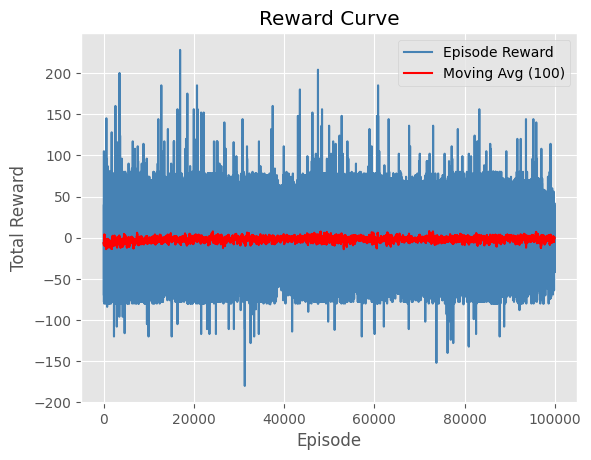

In [ ]:
# Train our DQN agent with true count and set his policy
task2_env = BlackjackDQNSimple(high_threshold = 7, low_threshold = -7, number_of_decks=number_of_decks, max_bet = max_bet) # thresholds have a different meaning here (clip true count)
policy_net, bet_net = deep_q_learning(environment = task2_env, tabular_policy=Q, episodes = 10 ** 5)
task2_env.set_policy(policy_net, bet_net)

In [ ]:
# Check betting policy based on our simple counting system
# Make necessary conversions to tensors and get q_values of network
device = next(task2_env.bet_policy.parameters()).device # get current device of model
bets = []
print("---- Betting Policy: ----")
for counting_state in range(task2_env.low_threshold, task2_env.high_threshold+1):
  state_tensor = counting_state_to_tensor(counting_state, task2_env).unsqueeze(0).to(device)

  with torch.no_grad():
    q_values = task2_env.bet_policy(state_tensor)[0]
    bet_action_idx = q_values.argmax().item()
    bet = task2_env.bet_actions[bet_action_idx]
    bets.append( bet )
    print(f"Bet when true count is {counting_state}: {bet}")

---- Betting Policy: ----
Bet when true count is -7: 23
Bet when true count is -6: 23
Bet when true count is -5: 16
Bet when true count is -4: 10
Bet when true count is -3: 21
Bet when true count is -2: 10
Bet when true count is -1: 5
Bet when true count is 0: 1
Bet when true count is 1: 17
Bet when true count is 2: 1
Bet when true count is 3: 32
Bet when true count is 4: 32
Bet when true count is 5: 32
Bet when true count is 6: 32
Bet when true count is 7: 1


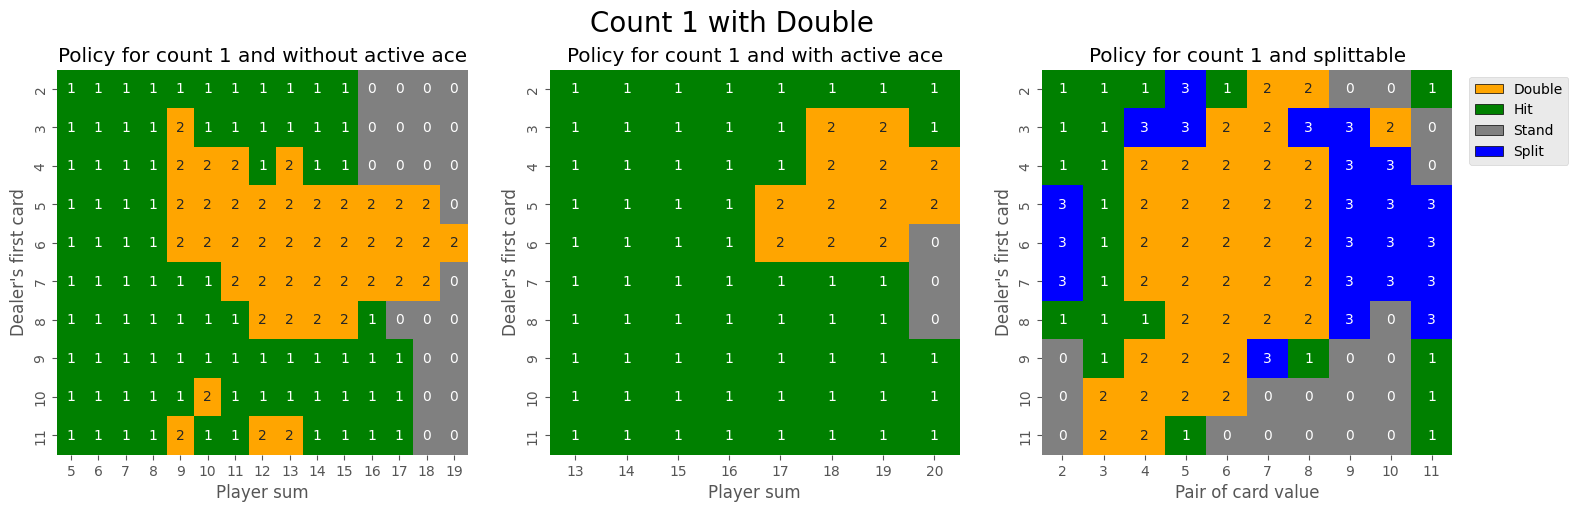

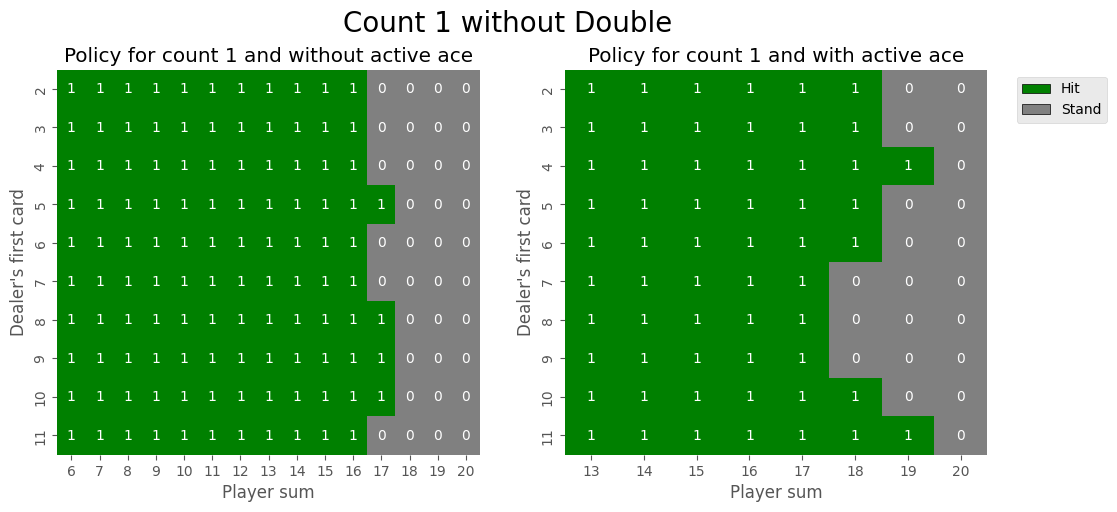

In [ ]:
# Use this to check the policy for specific count and bet (bet should be according to previous cell to check actual policy)
counting_state = 0
bet = 1
visualize_policy(task2_env,counting_state, bet, label = f"Count {bet}")

Training Progress: 100%|██████████| 100000/100000 [46:11<00:00, 36.08it/s]


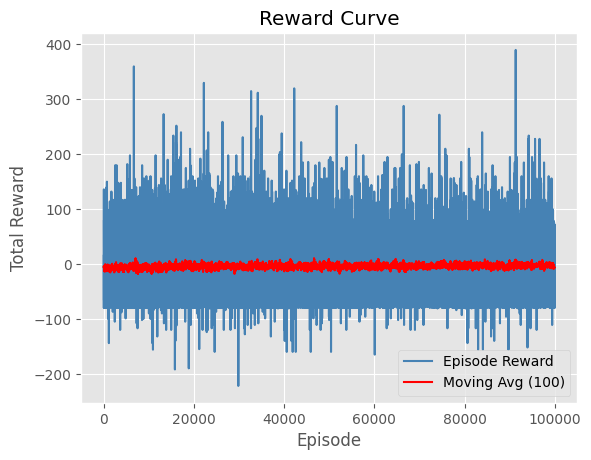

In [ ]:
# Train our DQN agent with complete count and set his policy
task2_env_complete = BlackjackDQNImproved(number_of_decks=number_of_decks, max_bet = max_bet) # thresholds are useless here
policy_net, bet_net = deep_q_learning(environment = task2_env_complete, episodes = 10 ** 5)
task2_env_complete.set_policy(policy_net, bet_net)

In [ ]:
# Check betting policy for specific counting state
device = next(task2_env_complete.bet_policy.parameters()).device # get current device of model
print("---- Betting Policy: ----")
counting_state = [0, 1, 1, 1, 1, 0, 1, 0, 3, 1,  2, 0, 0, 41]
                 #A, 2, 3, 4, 5, 6, 7, 8, 9, 10, J, Q, K, cards

state_tensor = counting_state_to_tensor(counting_state, task2_env_complete).unsqueeze(0).to(device)
with torch.no_grad():
  q_values = task2_env_complete.bet_policy(state_tensor)[0]
  bet_action_idx = q_values.argmax().item()
  bet = task2_env_complete.bet_actions[bet_action_idx]
  print(f"Bet for complete counting state {counting_state}: {bet}")

---- Betting Policy: ----
Bet for complete counting state [0, 1, 1, 1, 1, 0, 1, 0, 3, 1, 2, 0, 0, 41]: 39


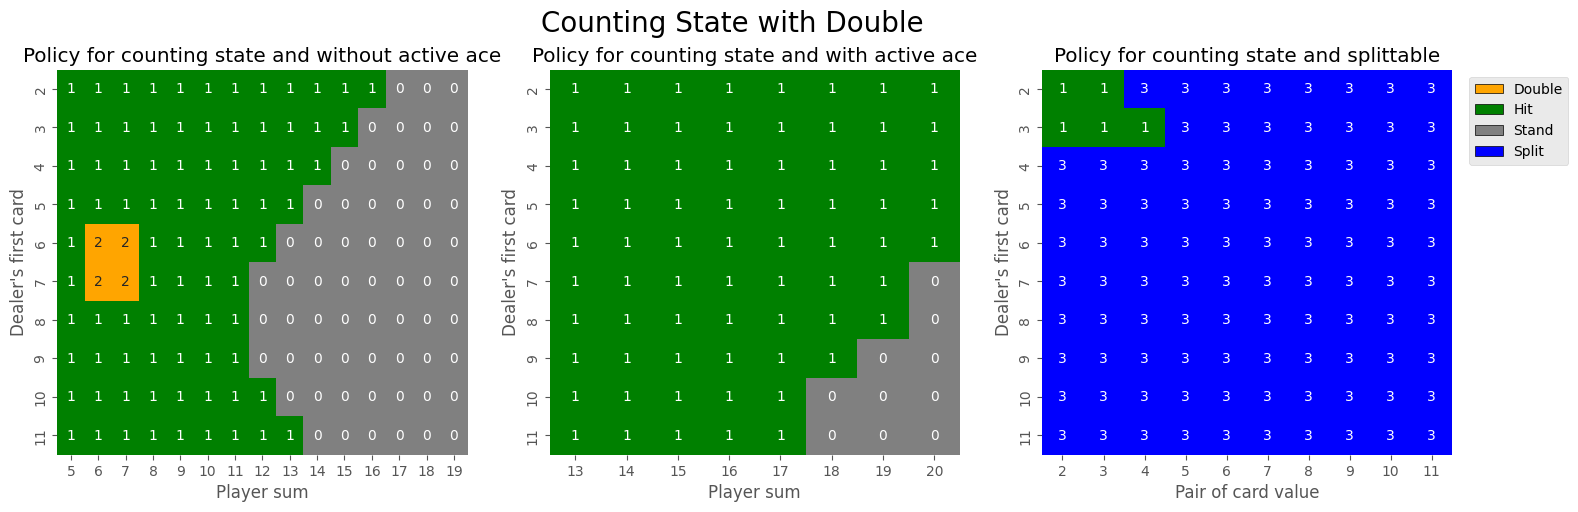

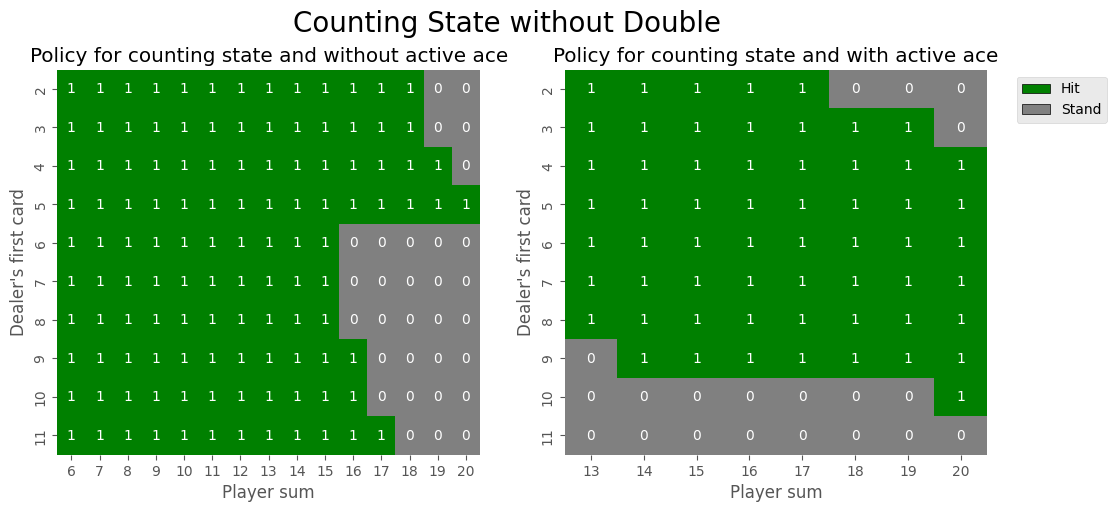

In [ ]:
# Use this to check the policy for specific count and bet (bet should be according to previous cell to check actual policy)
counting_state = [1, 2, 1, 1, 1, 0, 2, 0, 3, 1,  2, 0, 0, 37]
                 #A, 2, 3, 4, 5, 6, 7, 8, 9, 10, J, Q, K, cards
bet = 39
visualize_policy(task2_env_complete,counting_state, bet, label = f"Counting State")

### Test DQN

In [ ]:
# Test results for task 2 agent
episodes = 5 * 10 ** 5
wins1, losses1 = test(task2_env, episodes)

Testing Progress: 100%|██████████| 500000/500000 [11:34<00:00, 719.49it/s]


In [ ]:
# Profit per episode
print(f"Results for task 2 with DQN (true count):\nProfit per episode: {(wins1-losses1)/episodes}")

Results for task 2 with DQN (true count):
Profit per episode: -0.391235


In [ ]:
# Test results for task 2 agent
episodes = 5 * 10 ** 5
wins, losses = test(task2_env_complete, episodes)

Testing Progress: 100%|██████████| 500000/500000 [12:29<00:00, 666.67it/s]


In [ ]:
# Profit per episode
print(f"Results for task 2 with DQN (complete count):\nProfit per episode: {(wins-losses)/episodes}")

Results for task 2 with DQN (complete count):
Profit per episode: -1.825087


# Console With Agents

In [ ]:
# Now that we have trained our agents we can also see them play in console. Uncomment the agent you want to play
#blackjack_console(task1_env, max_bet=task1_env.max_bet) # task 1
blackjack_console(task2_env_tabular, max_bet=task2_env_tabular.max_bet) # task 2 with true count and tabular
#blackjack_console(task2_env, max_bet=task2_env.max_bet) # task 2 with true count and DQN
#blackjack_console(task2_env_complete, max_bet=task2_env_complete.max_bet) # task 2 with complete count and DQN

Welcome to Blackjack!

Max bet is:  40 €
Do you wish to play a new game? ['y'/'n']: y
Number of cards left in deck 52

Betting amount: 15

Dealer's first card: ('10', 'Hearts') 

--- Playing Hand 1 ---
Player's hand: [('4', 'Clubs'), ('4', 'Spades')] (Value: 8)
(8, 0, 10, True, True, 15)
hit

Player's hand: [('4', 'Clubs'), ('4', 'Spades'), ('K', 'Clubs')] (Value: 18)
(18, 0, 10, False, False, 15)
stand

--- Results ---
Dealer's hand: [('10', 'Hearts'), ('9', 'Clubs')] (Value: 19)

Final Result for Hand 1:
Player's hand: [('4', 'Clubs'), ('4', 'Spades'), ('K', 'Clubs')] (Value: 18)
Player loses 15€ (lower score) !

Do you wish to play a new game? ['y'/'n']: y
Number of cards left in deck 47

Betting amount: 15

Dealer's first card: ('7', 'Spades') 

--- Playing Hand 1 ---
Player's hand: [('Q', 'Diamonds'), ('2', 'Hearts')] (Value: 12)
(12, 0, 7, False, True, 15)
hit

Player's hand: [('Q', 'Diamonds'), ('2', 'Hearts'), ('8', 'Hearts')] (Value: 20)
(20, 0, 7, False, False, 15)
stand

---